# Emg3d pyGIMLI inversion for single value

Requires
- `pygimli>=1.5.2`
- ipygimli.py

v1: we here assume that we know the shape of the anomaly and the background and only invert for the value of the anomaly. A suite of simulations is created with different noise level, anomaly contrast, source distance, source type and frequency. Which should help to identify effects of the source distance and source type on the ability to resolve anomalies and on the limitations of the method for identifying small contrasts.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

import emg3d
import ipygimli as ipygimli
from Emg3d_extra_grid_functions_v26 import *
import h5py
import pandas as pd

In [2]:
#Random number regenerator used to set the noise, seed guarantees the same noise is reproduced each time, can be adapted with different numbers to test different noise
rng_real = np.random.default_rng(seed=0)
rng_imag = np.random.default_rng(seed=1)

#Note rather than generating 5 different noise manifestations as in the DGSA we here compute just one but this seems reasonable for the purpose

## Create synthetic data

Model used in previous forward-modeling (v1), with a cuboid hot plume inside

### Define fixed survey parameters

In [3]:
# Fixed survey parameters

# Receivers, vertical z-directed point dipoles
rec_x = np.arange(1, 41)*0
rec_y = np.array([74]*40)
rec_z = np.arange(1,41)*-7.5
rec_coords = (rec_x, rec_y, rec_z, 0.0, 90.0)
rec = emg3d.surveys.txrx_coordinates_to_dict(emg3d.RxElectricPoint, rec_coords)

# Layer boundaries
# We idealize the depth model here a bit, to have cells of 10m in depth
depth = [0, -50, -80, -120, -190]

# Layer resistivities in Ohm.m for the baseline
resistivities_base = np.array([1e8, 52.0, 38.0, 26.0, 29.5, 17.5]) # base incl. air (lower res, because of 3D modelling)

#Noise level, fixed
noise_floor = 1e-15
mean_noise = 0.0

### Create baseline model

In [4]:
grid = emg3d.construct_mesh(
    center=(0,0,0),                                 # Center of wanted grid
    frequency= 1,                            # Frequency we will use the grid for
    properties=[25, 1e8],                           # Reference resistivity
    domain=([-100, 100], [-100, 100], [-300, 0]),   # Domain in which we want precise results
    center_on_edge=True,
    min_width_limits = [25, 25, 5],
)
 
grid  # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 294,912 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     48   -105,390.51    105,390.51     25.00 31,649.36    1.43
   y     48   -105,390.51    105,390.51     25.00 31,649.36    1.43
   z    128   -106,386.28    137,173.52      5.00 31,082.24    1.29

In [5]:
#Insert resistivity values into the grid

# Pre-allocate an array with number of cells corresponding to our grid
res_base = np.ones(grid.shape_cells)

# Layered base model: Fill in layered resistivities into our grid and create model
dd = np.r_[np.inf, depth, -np.inf]
for i in range(len(resistivities_base)):
    res_base[:, :, (grid.cell_centers_z > dd[i+1]) & (grid.cell_centers_z <= dd[i])] = resistivities_base[i]

model_base = emg3d.Model(grid, property_x=res_base, mapping='Resistivity')
model_base_conductivity = emg3d.Model(grid, property_x=1/np.array(res_base), mapping='Conductivity')

### Define variable parameters to test with

In [6]:
# Variable survey parameters

# Source frequencies
frequencies = [1, 1000, 10000]

# Source coordinates
src_distances = [50, 100, 200, 400, 600, 900]
src_coords = []
for dist in src_distances:
    src_coords.append((-dist, 0, 0, 0.0, 0.0)) #Add the x-directed source
    src_coords.append((0, 74-dist, 0, 90.0, 0.0)) #Add the y-directed source

# Noise level, variable
relative_errors = [0.01, 0.05, 0.10, 0.20]

In [7]:
# Variable subsurface parameters

res_targets = [1, 10, 20, 25, 30, 33, 34]

In [8]:
#Create a parameter list

parameter_list = []
for freq in frequencies:
    for src_coord in src_coords:
        for error in relative_errors:
            for resT in res_targets:
                parameter_list.append([freq, src_coord, error, resT])
                parameter_list.append([freq, src_coord, error, resT])
                #saved as frequency, source distance, source type, noise, contrast

### Create target models

In [9]:
#Use predefined function to insert a cuboid inton the target layer

x_extent = 50
y_extent = 50
zmin = depth[4] #-190
zmax = depth[3] #-120

res_target2_list = []
model_target2_list = []
model_target2_conductivity_list = []
for resT in res_targets:
    res_target2 = change_grid_values(res_base.copy(), grid, x_extent, y_extent, zmin, zmax, resT)
    model_target2 = emg3d.Model(grid, property_x=res_target2, mapping='Resistivity')
    model_target2_conductivity = emg3d.Model(grid, property_x=1/np.array(res_target2), mapping='Conductivity')

    res_target2_list.append(res_target2)
    model_target2_list.append(model_target2)
    model_target2_conductivity_list.append(model_target2_conductivity)

[-49, -49, -189] [49, 49, -121]
x:  -37.50000000000071
y:  -37.50000000000071
z:  -187.49999999998926
x:  37.49999999999929
y:  37.49999999999929
z:  -122.49999999998926
x bounds:  -37.50000000000071  ,  37.49999999999929
y_bounds:  -37.50000000000071  ,  37.49999999999929
z_bounds:  -187.49999999998926  ,  -122.49999999998926
[-49, -49, -189] [49, 49, -121]
x:  -37.50000000000071
y:  -37.50000000000071
z:  -187.49999999998926
x:  37.49999999999929
y:  37.49999999999929
z:  -122.49999999998926
x bounds:  -37.50000000000071  ,  37.49999999999929
y_bounds:  -37.50000000000071  ,  37.49999999999929
z_bounds:  -187.49999999998926  ,  -122.49999999998926
[-49, -49, -189] [49, 49, -121]
x:  -37.50000000000071
y:  -37.50000000000071
z:  -187.49999999998926
x:  37.49999999999929
y:  37.49999999999929
z:  -122.49999999998926
x bounds:  -37.50000000000071  ,  37.49999999999929
y_bounds:  -37.50000000000071  ,  37.49999999999929
z_bounds:  -187.49999999998926  ,  -122.49999999998926
[-49, -49, -1

In [1]:
index = 0

#Focus on the y,z plane
f0 = grid.plot_slice(
    np.ravel(model_target2_list[index].property_x, 'F'),
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=1, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[1], rec_coords[2], 'bv', markersize = 10)
axs[1].plot(parameter_list[index][1][1], parameter_list[index][1][2], 'r*', markersize = 20)
axs[1].grid(False)
fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

NameError: name 'grid' is not defined

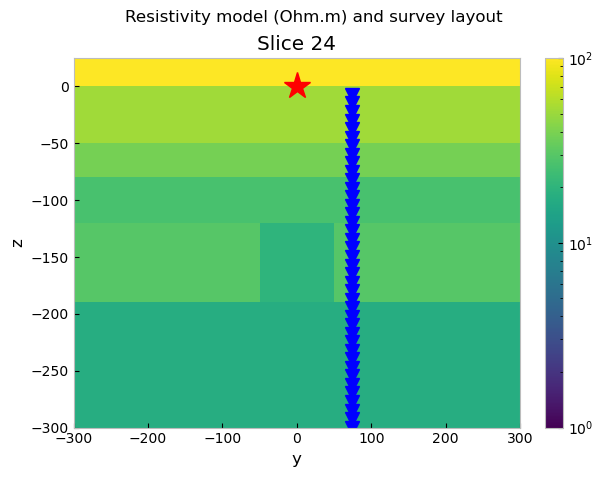

In [11]:
index = 2

#Focus on the y,z plane
f0 = grid.plot_slice(
    1/model_target2_conductivity_list[index].property_x,
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=1, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[1], rec_coords[2], 'bv', markersize = 10)
axs[1].plot(parameter_list[index][1][1], parameter_list[index][1][2], 'r*', markersize = 20)
axs[1].grid(False)
fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

### Create the simulated data

Code is based on sensitivity gradient notebook v1_7

We want to create a simulation class with the true model data + noise as observed data and the starting model as the model

In [12]:
#Generate frequency- and source-dependent grids
gopts = {
    'properties': [25, 1e8],
    'min_width_limits': [25, 25, 5],
    #'stretching': (None, None, [1.0, 1.5]),
    'domain': (
        [-100, 100],
        [-100, 100],
        [-300, 0]
    ),
    'center_on_edge': False,
}

In [13]:
#Create surveys, important to use different names for each survey to prevent complications

surveys = []

for i in np.arange(len(parameter_list)):
    freq = parameter_list[i][0]
    src_coord = parameter_list[i][1]
    src = emg3d.surveys.txrx_coordinates_to_dict(emg3d.TxElectricDipole, src_coord)
    
    surveys.append(emg3d.surveys.Survey(
        name='Survey '+str(i),  # Name of the survey
        sources=src,               # Source coordinates
        receivers=rec,             # Receiver coordinates
        frequencies=freq,   # Two frequencies
        # data=data,               # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
        ))

In [43]:
# simulate with the true model to create the observed data

simulations = []
increment = len(parameter_list)/len(res_targets)

for i in np.arange(len(parameter_list)):

    resT_index = int((i-i%increment)/increment)

    simulations.append(emg3d.simulations.Simulation(
                name='Observed data simulation '+str(i),    # A name for this simulation
                survey=surveys[i],        # Our survey instance
                model=model_target2_conductivity_list[resT_index],          # The model
                gridding='both',      # Frequency- and source-dependent meshes
                max_workers=1,        # How many parallel jobs
                # solver_opts,        # Any parameter to pass to emg3d.solve
                gridding_opts=gopts,  # Gridding options
                receiver_interpolation = "linear" #Needed for correct computation of the gradient
            ))

    simulations[i].compute(observed=True)
    #The simulation should now contain observed data (+noise), synthetic data (without noise) and standard deviation values
    #The survey class is also updated with this information

Compute efields            0/1  [00:00]

Compute efields            0/1  [00:00]

Compute efields            0/1  [00:00]

Compute efields            0/1  [00:00]

Compute efields            0/1  [00:00]

Compute efields            0/1  [00:00]

... (2,006 outputs left out)

Compute efields            0/1  [00:00]

Compute efields            0/1  [00:00]

Compute efields            0/1  [00:00]

Compute efields            0/1  [00:00]

In [46]:
# Re-compute the noise and overwrite the data, based on empymod+pygimli testing

dobs0_list = []
noise0_list = []
for i in np.arange(len(parameter_list)):
    dobs = surveys[i].data['synthetic']
    relative_error = parameter_list[i][2]

    # Add random white noise to dobs
    std_dev_real = np.sqrt(noise_floor**2 + np.abs(relative_error*dobs.real)**2)
    std_dev_imag = np.sqrt(noise_floor**2 + np.abs(relative_error*dobs.imag)**2)
    noise_real = rng_real.normal(loc=0, scale=std_dev_real, size = dobs.shape)
    noise_imag = rng_imag.normal(loc=0, scale=std_dev_imag, size = dobs.shape)
    std_dev = std_dev_real + 1j*std_dev_imag
    noise = noise_real + 1j*noise_imag
    dobs += noise
    dobs0_list.append(dobs)
    noise0_list.append(noise)

    # Overwrite values in survey
    surveys[i].data['observed'] = dobs
    surveys[i].standard_deviation = std_dev

In [49]:
surveys2 = []

for i in np.arange(len(parameter_list)):
    freq = parameter_list[i][0]
    src_coord = parameter_list[i][1]
    src = emg3d.surveys.txrx_coordinates_to_dict(emg3d.TxElectricDipole, src_coord)

    surveys2.append(emg3d.surveys.Survey(
        name='Inversion survey'+str(i),  # Name of the survey
        sources=src,               # Source coordinates
        receivers=rec,             # Receiver coordinates
        frequencies=freq,   # Two frequencies
        data=surveys[i].data['observed'], # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
    ))
    
    surveys2[i].standard_deviation = surveys[i].standard_deviation

In [ ]:
simulations2 = []

for i in np.arange(len(parameter_list)):
    
    simulations2.append(emg3d.simulations.Simulation(
                name='Inversion simulation '+str(i),    # A name for this simulation
                survey=surveys2[i],        # Our survey instance
                model=model_base_conductivity,          # The model
                gridding='both',      # Frequency- and source-dependent meshes
                max_workers=1,        # How many parallel jobs
                # solver_opts,        # Any parameter to pass to emg3d.solve
                gridding_opts=gopts,  # Gridding options
                receiver_interpolation = "linear", #Needed for correct computation of the gradient
                tqdm_opts = False #To switch-off progress bar during inversion
            ))

    simulations2[i].compute(observed=False)

    #We don't put observed=True in this case because this will overwrite the observed data saved inside the survey

(179.5, 180.0)

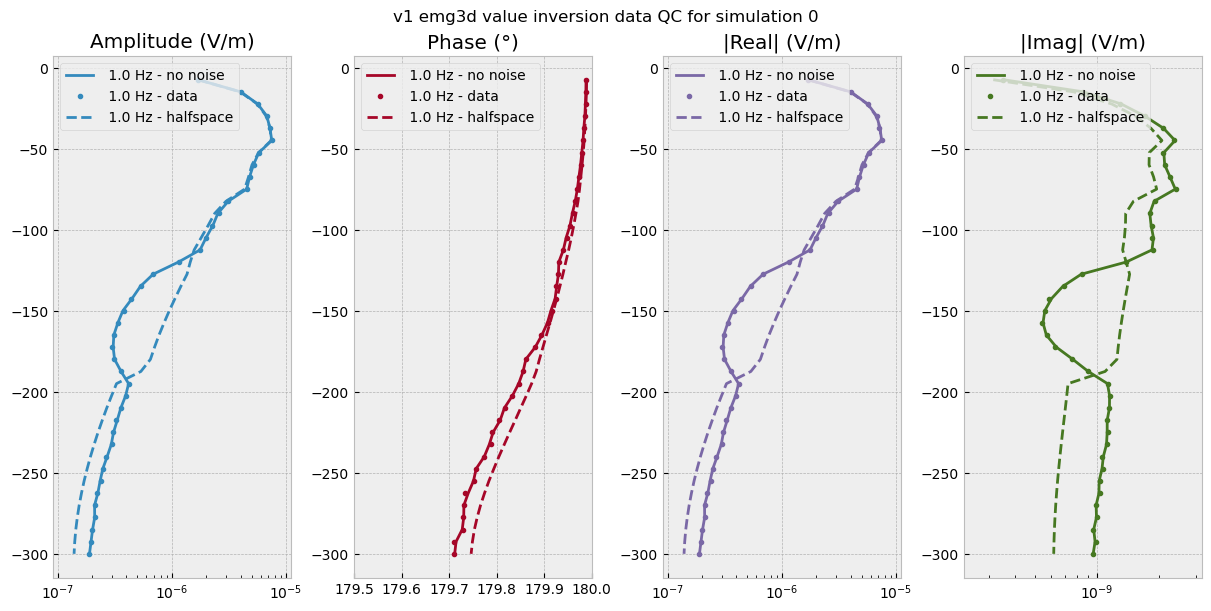

In [52]:
index = 0

# QC data
dobs = np.array(dobs0_list[index])[0,:,0]
noise = np.array(noise0_list[index])[0,:,0]
dhalf = np.array(surveys2[index].data['synthetic'])[0,:,0]
frequency = parameter_list[index][0]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]


plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data_half = [np.abs(dhalf), np.angle(dhalf,deg=True), abs(dhalf.real), abs(dhalf.imag)]
fig.suptitle("v1 emg3d value inversion data QC for simulation "+str(index))
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - no noise")
    ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - data")
    ax.plot(data_half[j][:], rec_coords[2], 'C'+str(j)+'--', label=f"{frequency: 2.1f} Hz - halfspace")
    ax.legend(loc='upper left')
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])
#The noise looks very acceptable

## Define regions, instantiate Kernel and Inversion

We only invert for the value of the anomaly, not the location, by marking the region of the anomaly and using single=True in pyGIMLi's region manager

In [55]:
# Create region markers, same for all simulatgions
markers = np.zeros(simulations2[0].model.shape, dtype=int)
markers[model_target2_list[0].property_x < 15] = 1       # Only target is free

#We use model with index 0 to compute this because it has the highest contrast, allowing the selection method with res < 15 to work

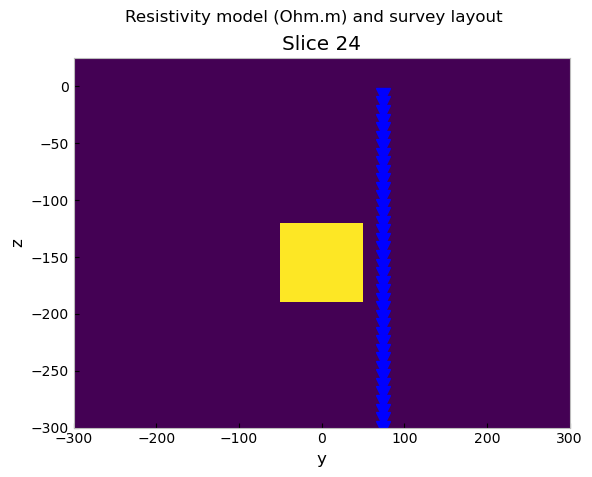

In [56]:
# QC the inversion region corresponds to the wanted region
# #Focus on the y,z plane
grid.plot_slice(
    markers,
    normal = 'X',
    #pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[1], rec_coords[2], 'bv', markersize = 10)
#axs[1].plot(parameter_list[index][1][1], parameter_list[index][1][2], 'r*', markersize = 20)
axs[1].grid(False)

In [ ]:
fops = []
INVs = []

for i in np.arange(len(parameter_list)):
    # Instantiate the emg3d-kernel for pyGIMLi
    fops.append(ipygimli.Kernel(simulation=simulations2[i], markers=markers, pgthreads=1))

    # Instantiate the inversion and set some inversion parameters
    INVs.append(ipygimli.Inversion(fop=fops[i]))
    #INV.inv.setCGLSTolerance(1)  # is _absolute_, not _relative_
    INVs[i].inv.setMaxCGLSIter(10)

    # Set the regions.
    INVs[i].fop.setRegionProperties(1, single=True, limits=(0.01, 2)) # Target
    INVs[i].fop.setRegionProperties(0, background=True) # Background

## Run inversion

In [ ]:
for i in np.arange(len(parameter_list)):
    INVs[i].run(
        #maxIter=2, # just to test
        lam=20,  # btw 1-100
        lambdaFactor=10,
        stopAtChi1=False,
        dPhi=1.0,
        #verbose=True,
        #debug=True,
        #startModel=model.property_x.ravel('F'),
        #isReference=True, 
    )

24/08/26 - 20:08:47 - pyGIMLi - INFO - :: pyGIMLi(emg3d) START ::
24/08/26 - 20:08:56 - pyGIMLi - INFO - ===========================================================================
                                        it   F(m)         χ²          λ         ϕᵈ         ϕᵐ   ϕ=ϕᵈ+λϕᵐ   Δϕ (%)
                                       ---------------------------------------------------------------------------
24/08/26 - 20:08:56 - pyGIMLi - INFO -   0      1      491.4       20.0    39311.6       19.4    39700.6     0.00
24/08/26 - 20:09:19 - pyGIMLi - INFO -   1     24      430.4       20.0    34434.8       16.5    34765.3    12.43
24/08/26 - 20:09:42 - pyGIMLi - INFO -   2     24      215.7      200.0    17253.5        8.5    18950.7    45.49
24/08/26 - 20:10:05 - pyGIMLi - INFO -   3     24       21.8     2000.0     1743.4        1.4     4463.2    76.45
24/08/26 - 20:10:27 - pyGIMLi - INFO -   4     24        0.8    20000.0       61.3        0.0      102.8    97.70
24/08/26 - 20:10:41 

## Save inversion information as responses

In [ ]:
# Load relevant inversion parameters saved through post_step (ipygimli functionality)
inv_datas = []
phi_histories = []

for i in np.arange(len(parameter_list)):
    inv_datas.append(h5py.File(f"Inversion simulation {i}.h5",'r'))

    phi_history = []
    for i in np.arange(len(INVs[i].modelHistory)):
        phi_history.append(int(np.array(inv_datas[i]['invinfo'][str(i)]['phi'])))

    phi_histories.append(phi_history)

In [ ]:
# recall: params_list.append([anom_res, thick, depth, relative_error, i])

parameters = np.zeros((len(parameter_list), len(parameter_list[0])+1))
parameters[:,:4] = np.array(parameter_list)
#print(np.shape(parameters))

responses = np.empty((parameters.shape[0], 5), dtype="float64")
for i in np.arange(len(parameter_list)):
    parameters[i,4] = i%2 #Reflects x- or y-directed source
    parameters[i,1] = parameter_list[i][i%2]

    res_fitted = 1/INVs[i].modelHistory[-1]
    res_true = parameter_list[i][3]

    responses[i,0] = phi_histories[i][-1] #Remanent misfit phi
    responses[i,1] = INVs[i].chi2History[-1] #Final chi2 value
    responses[i,2] = len(INVs[i].chi2History) #Average amount of iterations
    responses[i,3] = np.abs(res_fitted-res_true) #Anomaly error (absolute)
    responses[i,4] = responses[i,3]/res_true #Anomaly error (relative)

In [ ]:
#Save information

np.savetxt("20260825_emg3d_pyGIMLi_value_inversion_v1_parameters.txt", parameters)
np.savetxt("20260825_emg3d_pyGIMLi_value_inversion_v1_responses.txt", responses)

In [ ]:
#Look at the values together

all_sim_info = np.zeros((parameters.shape[0], parameters.shape[1]+responses.shape[1]))
all_sim_info[:,:parameters.shape[1]] = parameters
all_sim_info[:,parameters.shape[1]:] = responses
table = pd.DataFrame(all_sim_info, columns = ["frequency", "distance", "rel_noise", "anom_res", "y-source", 'Phi', 'Chi2', 'Iterations', 'Abs. deviation', 'Rel. deviation'])
table = table.sort_values(by=["Rel. deviation"])
display(table)

## Plots

Text(0.5, 1.0, 'Inversion information')

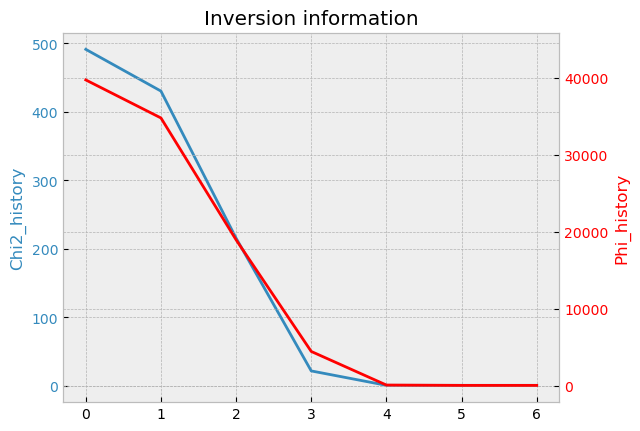

In [ ]:
index = 0

fig, ax = plt.subplots()

ax.plot(INVs[index].chi2History)
ax.tick_params(axis='y', labelcolor='C0')
ax.set_ylabel('Chi2_history', color = 'C0')
ax2 = ax.twinx()
ax2.plot(phi_histories[index], c = 'red')
ymin, ymax = ax2.get_ylim()
ax2.set_ylim([ymin*1.1, ymax*1.1])
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylabel('Phi_history', c='red')
ax.set_title('Value-only v1 script: Inversion information, simulation '+str(index))

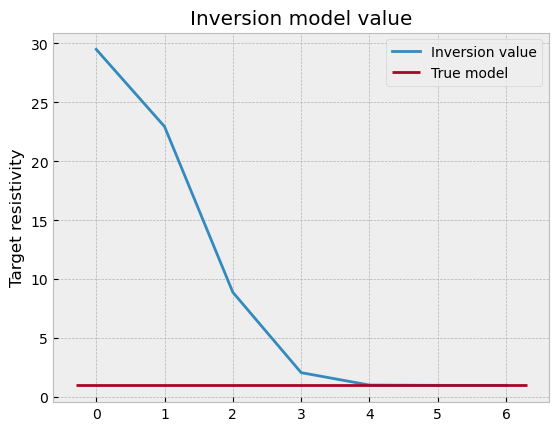

In [ ]:
index = 0
resT_index = np.round((i+1)/len(res_targets)- i%res_targets)

fig, ax = plt.subplots()

ax.plot(1/np.array(INVs[index].modelHistory), label='Inversion value')
ax.set_ylabel('Target resistivity')
ax.set_title('Value-only v1 script: Inversion model value, simulation'+str(index))
xmin, xmax = ax.get_xlim()
ax.hlines(y = res_targets[resT_index], xmin=xmin, xmax=xmax, color='C1', label= 'True model')
ax.legend()

Text(0.5, 0.98, 'Resistivity models (Ohmm) per iteration')

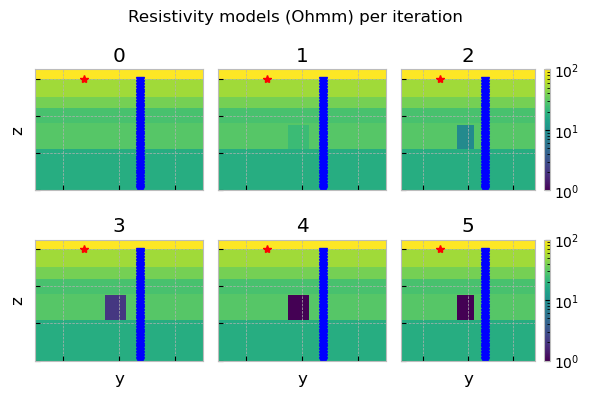

In [ ]:
#Code adapted from plot_models function in sampledata.py

index = 0

sim_amount = len(INVs[index].chi2History)
n_rows = 2
n_columns = 3
depth = 150
vmin = 1e0
vmax = 100

popts = {'cmap': 'viridis', 'norm': LogNorm(vmin=vmin, vmax=vmax)} #Normalize(vmin=vmin, vmax=vmax)}
# popts2 = {'edgecolors': 'grey', 'linewidth': 0.5, 'cmap': 'Spectral_r',
#           'norm': LogNorm(vmin=0.1, vmax=1000)}
opts = {'v_type': 'CC', 'normal': 'X', 'range_x': [-300, 300], 'range_y': [-300, 25],}

fig, axs = plt.subplots(n_rows, n_columns, figsize=(n_columns*2, n_rows*2), tight_layout=True, sharex = True, sharey = True)

for i in np.arange(sim_amount-1):
    ax=axs[int((i-i%n_columns)/n_columns), i%n_columns]
    m_it = 1/fop.model2emg3d(INV.modelHistory[i])

    # Plotting the model
    out = grid.plot_slice(m_it, ax=ax, pcolor_opts=popts, **opts)
    ax.set_title(str(i))
    ax.plot(rec_coords[1], rec_coords[2], 'bv')
    ax.plot(src_coords[1], src_coords[2], 'r*')
    if i%n_columns != 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])
        if i%n_columns == n_rows:
            plt.colorbar(out[0], ax=ax)#, fraction=.5, shrink=.8, aspect=30)
    
for i in np.arange(sim_amount-1-n_columns):
        ax=axs[int((i-i%n_columns)/n_columns), i%n_columns]
        ax.set_xlabel('')
        ax.set_xticklabels([])

    #for ax in axs.ravel():
    #    ax.axis('equal')
fig.suptitle('Value-only script v1: Res. models (Ohmm) /iteration, simulation '+str(index))



(179.5, 180.0)

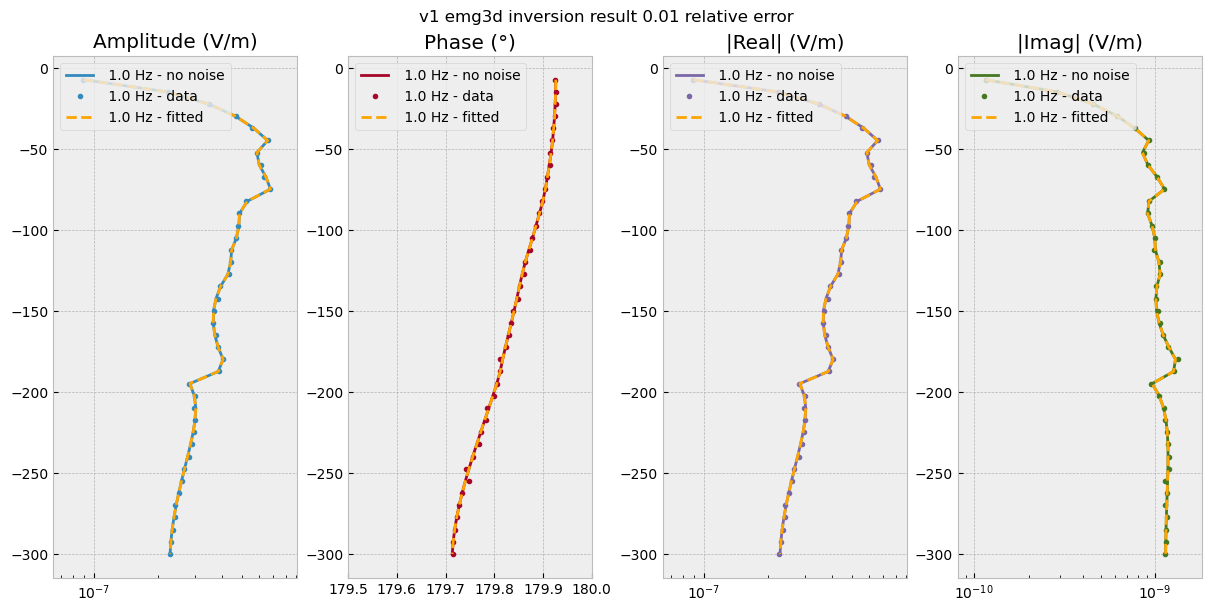

In [ ]:
# QC data
index = 0

dobs = np.array(dobs0_list[index])[0,:,0]
noise = np.array(noise0_list[index])[0,:,0]
response = simulations2[index].survey.data.synthetic[0,:,0]
#True response
#response = fops[index].data2emg3d(fops[index].response(fops[index].model2gimli(model_target2_conductivity_list[index].property_x)))[0,:,0]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]


plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data_inv = [np.abs(response), np.angle(response,deg=True), abs(response.real), abs(response.imag)]
fig.suptitle("Value-only script v1 emg3d inversion result, simulation "+str(index))
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - no noise")
    ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - data")
    ax.plot(data_inv[j][:], rec_coords[2], color= 'orange', linestyle='--', label=f"{frequency: 2.1f} Hz - fitted")
    ax.legend(loc='upper left')
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])
#The noise looks very acceptable

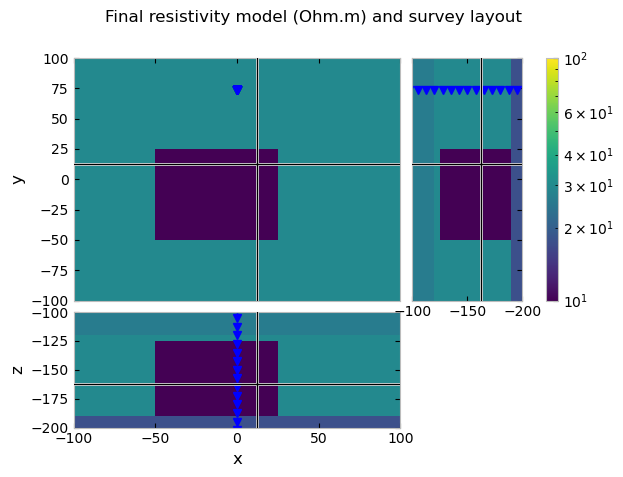

In [ ]:
index = 0

#QC cube location
grid.plot_3d_slicer(
    1/fops[index].model2emg3d(INVs[index].modelHistory[-1]),
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -100],
    zslice=-160,
)
# Plot survey in figure above
fig = plt.gcf()
fig.suptitle('Final resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[0], rec_coords[1], 'bv')
axs[2].plot(rec_coords[0], rec_coords[2], 'bv')
axs[3].plot(rec_coords[2], rec_coords[1], 'bv')
axs[1].plot(src_coords[0], src_coords[1], 'r*')
axs[2].plot(src_coords[0], src_coords[2], 'r*')
axs[3].plot(src_coords[2], src_coords[1], 'r*')
axs[1].grid(False)
axs[2].grid(False)
axs[3].grid(False)

In [8]:
emg3d.Report()

--------------------------------------------------------------------------------
  Date: Tue Sep 10 17:08:40 2024 CEST

                OS : Linux (Ubuntu 22.04)
            CPU(s) : 16
           Machine : x86_64
      Architecture : 64bit
               RAM : 31.0 GiB
       Environment : Jupyter
       File system : ext4

  Python 3.11.9 | packaged by conda-forge | (main, Apr 19 2024, 18:36:13) [GCC
  12.3.0]

             numpy : 1.26.4
             scipy : 1.14.0
             numba : 0.59.1
             emg3d : 1.8.4.dev6+gd2f88de
           empymod : 2.3.1
            xarray : 2024.6.0
        discretize : 0.10.0
              h5py : 3.11.0
        matplotlib : 3.9.1
              tqdm : 4.66.4
           IPython : 8.26.0
           pygimli : 1.5.2
            pgcore : 1.5.0
--------------------------------------------------------------------------------